# Bab 4 — Introduction to Neural Learning: Gradient Descent

**Acuan:** Trask, *Grokking Deep Learning*, Bab 4, hlm. 47–77. Contoh perhitungan dan grafik ditulis ulang secara mandiri.

**Tujuan belajar:** menghubungkan error dengan perubahan bobot, memahami turunan, learning rate, konvergensi/divergensi, dan membedakan hafalan satu contoh dari generalisasi.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x, target = 2.0, 1.0
weight = 0.1
def squared_error(weight, x=x, target=target):
    return (x * weight - target) ** 2

print('Prediksi awal:', x * weight)
print('Squared error awal:', squared_error(weight))

Prediksi awal: 0.2
Squared error awal: 0.6400000000000001


## 1. Predict → compare → learn

Untuk satu contoh, gunakan $L(w)=(xw-y)^2$. Selisih $\delta=\hat y-y$ menyimpan **arah** kesalahan. Turunan eksak $dL/dw=2(xw-y)x=2\delta x$. Banyak demonstrasi buku menyerap faktor 2 ke learning rate, sehingga bisa memakai $\delta x$; keduanya benar jika learning rate disesuaikan. Di notebook ini kita memakai turunan eksak dan menuliskan konvensinya secara eksplisit.

In [2]:
prediction = x * weight
delta = prediction - target
analytic_gradient = 2 * delta * x
epsilon = 1e-6
numeric_gradient = (squared_error(weight + epsilon) - squared_error(weight - epsilon)) / (2 * epsilon)
print('Delta:', round(delta, 4))
print('Gradien analitik:', round(analytic_gradient, 4))
print('Gradien beda hingga:', round(numeric_gradient, 4))
assert np.isclose(analytic_gradient, numeric_gradient, atol=1e-6)

Delta: -0.8
Gradien analitik: -3.2
Gradien beda hingga: -3.2


## 2. Dari hot-and-cold ke gradien

Metode *hot-and-cold* membandingkan loss setelah bobot dinaikkan dan diturunkan sedikit, lalu memilih arah yang lebih baik. Ini memperkirakan arah, tetapi membutuhkan evaluasi tambahan untuk tiap kemungkinan langkah. Turunan memberikan arah dan sensitivitas lokal secara langsung. Pembaruan gradient descent adalah $w_{t+1}=w_t-\alpha\,dL/dw$, dengan $\alpha>0$ sebagai learning rate.

In [3]:
step = 0.01
print('Loss jika bobot diturunkan:', round(squared_error(weight - step), 4))
print('Loss jika bobot dinaikkan:', round(squared_error(weight + step), 4))
alpha = 0.05
updated = weight - alpha * analytic_gradient
print('Bobot baru:', round(updated, 4), 'loss baru:', round(squared_error(updated), 4))
assert squared_error(updated) < squared_error(weight)

Loss jika bobot diturunkan: 0.6724
Loss jika bobot dinaikkan: 0.6084
Bobot baru: 0.26 loss baru: 0.2304


## 3. Beberapa iterasi dan learning rate

Learning rate terlalu kecil bergerak lambat; terlalu besar dapat melompati minimum dan menyebabkan osilasi/divergensi. Untuk fungsi kuadrat sederhana ini, kita dapat melihat efeknya tanpa variabel lain. Konvergensi pada **training example yang sama** tidak membuktikan bahwa bobot bekerja pada input baru.

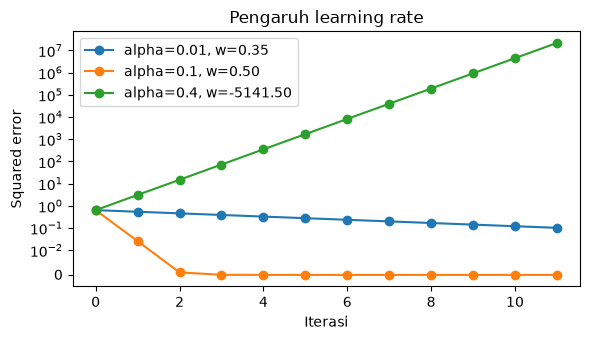

Bobot optimum untuk satu contoh: 0.5


In [4]:
def train_scalar(alpha, iterations=12):
    w = 0.1
    history = []
    for _ in range(iterations):
        history.append(squared_error(w))
        w -= alpha * 2 * (x * w - target) * x
    return w, np.array(history)

fig, ax = plt.subplots(figsize=(6, 3.5))
for lr in [.01, .10, .40]:
    final_w, history = train_scalar(lr)
    ax.plot(history, marker='o', label=f'alpha={lr}, w={final_w:.2f}')
ax.set(xlabel='Iterasi', ylabel='Squared error', title='Pengaruh learning rate')
ax.set_yscale('symlog', linthresh=.01)
ax.legend(); plt.tight_layout(); plt.show()
print('Bobot optimum untuk satu contoh:', target / x)

## 4. Dari satu contoh ke beberapa contoh

Jika ada $n$ pasangan, loss rata-rata $L(w)=\frac1n\sum_i(wx_i-y_i)^2$ mempunyai gradien $\frac{2}{n}\sum_i (wx_i-y_i)x_i$. Gradien ini merangkum tekanan semua contoh; contoh yang menginginkan pembaruan berlawanan arah dapat saling menyeimbangkan. Pembaruan pada seluruh dataset disebut full-batch gradient descent. Kita sengaja tidak menambahkan bias agar formula tetap satu parameter.

In [5]:
inputs = np.array([1., 2., 3., 4.])
goals = np.array([.5, 1., 1.5, 2.])  # hubungan sintetis y=0.5x
w = -0.2
losses = []
for _ in range(150):
    errors = w * inputs - goals
    losses.append(np.mean(errors**2))
    gradient = 2 * np.mean(errors * inputs)
    w -= .02 * gradient
print('Bobot belajar:', round(w, 4), 'MSE akhir:', round(losses[-1], 8))
assert np.isclose(w, .5, atol=1e-3)

Bobot belajar: 0.5 MSE akhir: 0.0


### Ringkasan dan refleksi

- Error memberi besar penyimpangan; gradien memberi arah pembaruan yang menurunkannya secara lokal.
- Turunan bisa diperiksa dengan *finite difference* untuk menangkap kesalahan aljabar/kode.
- Learning rate adalah bagian penting dari algoritme; nilai besar tidak selalu lebih cepat.
- Menghafal satu pasangan input–target berbeda dari mempelajari pola yang berlaku pada contoh baru. Evaluasi generalisasi masih diperlukan.